<a href="https://colab.research.google.com/github/tso-eng/Machine-Learning-Sciktlearn/blob/Engenharia-de-Processo---Etanol-de-Milho/Modelo_Hibrido_Cin%C3%A9tica_Fermenta%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

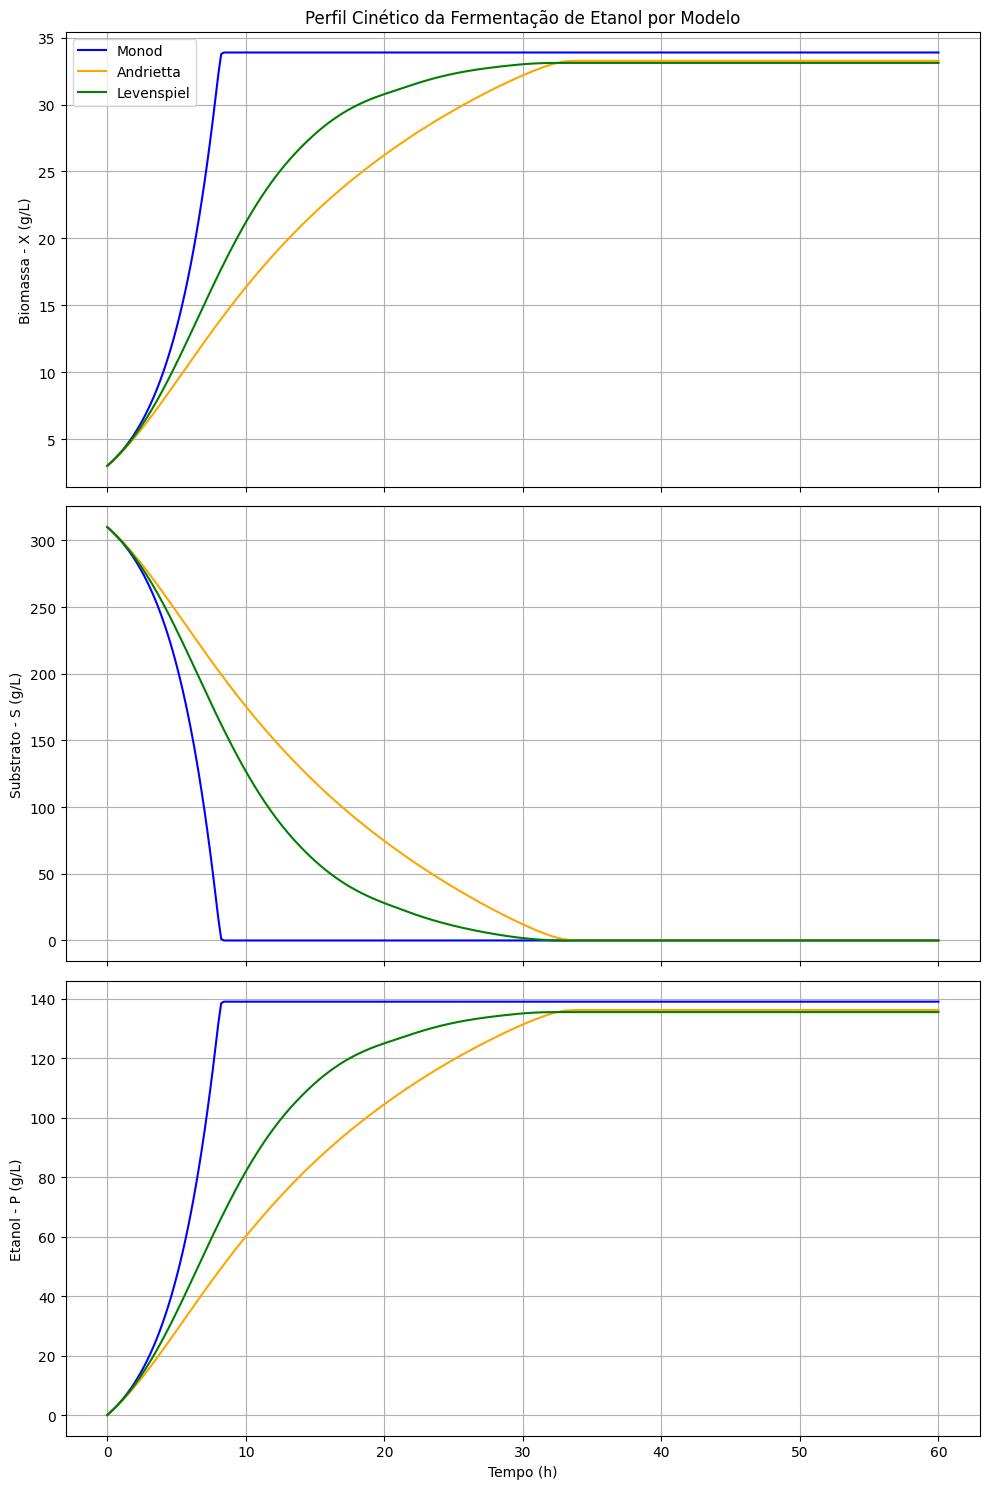

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definição dos Modelos Cinéticos ---

# Modelo de Monod clássico (sem inibição pelo produto)
def kinetics_monod(X, S, P, params):
    mu_max = params['mu_max']
    Ks = params['Ks']
    mu = mu_max * S / (Ks + S)
    return mu

# Modelo de Silvio Andrietta (inibição pelo produto com termo exponencial)
def kinetics_andrietta(X, S, P, params):
    mu_max = params['mu_max']
    Ks = params['Ks']
    Ki = params['Ki'] # constante de inibição por células/produto
    # Representação típica do modelo de Andrietta adaptado para inibição por etanol
    mu = (mu_max * S / (Ks + S)) * np.exp(-P / Ki)
    return mu

# Modelo de Levenspiel (inibição pelo produto com expoente n)
def kinetics_levenspiel(X, S, P, params):
    mu_max = params['mu_max']
    Ks = params['Ks']
    Pm = params['Pm'] # Concentração máxima de produto limitante
    n = params['n']   # Índice de toxicidade do produto

    if P < Pm:
        mu = (mu_max * S / (Ks + S)) * ((1 - P / Pm) ** n)
    else:
        mu = 0.0
    return mu

# --- 2. Balanço de Massa (Equações Diferenciais) ---
def fermentation_ode(t, y, model_type, params):
    X, S, P = y

    # Parâmetros de rendimento e manutenção
    Y_xs = params['Y_xs']  # Rendimento de biomassa por substrato
    Y_ps = params['Y_ps']  # Rendimento de produto por substrato
    m_s = params['m_s']    # Coeficiente de manutenção

    # Escolha do modelo cinético de crescimento
    if model_type == 'monod':
        mu = kinetics_monod(X, S, P, params)
    elif model_type == 'andrietta':
        mu = kinetics_andrietta(X, S, P, params)
    elif model_type == 'levenspiel':
        mu = kinetics_levenspiel(X, S, P, params)
    else:
        mu = 0.0

    # Taxas de variação se houver substrato disponível
    if S > 1e-3:
        dXdt = mu * X
        dSdt = - (mu * X / Y_xs) - (m_s * X)
        dPdt = Y_ps * (mu * X / Y_xs)
    else:
        dXdt = 0.0
        dSdt = 0.0
        dPdt = 0.0

    return [dXdt, dSdt, dPdt]

# --- 3. Parâmetros e Condições Iniciais ---

# Chutes iniciais típicos de parâmetros cinéticos para Saccharomyces cerevisiae
params = {
    'mu_max': 0.3,       # Taxa específica de crescimento máxima (h^-1)
    'Ks': 2.0,           # Constante de semi-saturação (g/L)
    'Ki': 45.0,          # Constante de inibição de Andrietta (g/L)
    'Pm': 145.0,          # Concentração máxima de etanol tolerada por Levenspiel (g/L)
    'n': 1.5,            # Coeficiente de Levenspiel
    'Y_xs': 0.10,        # Rendimento de biomassa/substrato (g/g)
    'Y_ps': 0.45,        # Rendimento de produto/substrato (g/g)
    'm_s': 0.01          # Coeficiente de manutenção (g/g.h)
}

# Condições iniciais (g/L)
X0 = 3.0   # Concentração de inoculo de levedura
S0 = 310.0 # Açúcares redutores totais (g/L)
P0 = 0.0   # Etanol inicial

y0 = [X0, S0, P0]
t_span = (0, 60) # Intervalo de simulação em horas
t_eval = np.linspace(t_span[0], t_span[1], 300)

# --- 4. Resolução das Equações Diferenciais ---

results = {}
modelos = ['monod', 'andrietta', 'levenspiel']

for model in modelos:
    sol = solve_ivp(
        fermentation_ode,
        t_span,
        y0,
        args=(model, params),
        t_eval=t_eval,
        method='RK45'
    )
    results[model] = sol

# --- 5. Visualização Gráfica ---

fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True)
cores = {'monod': 'blue', 'andrietta': 'orange', 'levenspiel': 'green'}

for model in modelos:
    sol = results[model]
    axes[0].plot(sol.t, sol.y[0], label=f'{model.capitalize()}', color=cores[model])
    axes[1].plot(sol.t, sol.y[1], color=cores[model])
    axes[2].plot(sol.t, sol.y[2], color=cores[model])

axes[0].set_ylabel('Biomassa - X (g/L)')
axes[0].legend()
axes[0].grid(True)
axes[0].set_title('Perfil Cinético da Fermentação de Etanol por Modelo')

axes[1].set_ylabel('Substrato - S (g/L)')
axes[1].grid(True)

axes[2].set_ylabel('Etanol - P (g/L)')
axes[2].set_xlabel('Tempo (h)')
axes[2].grid(True)

plt.tight_layout()
plt.show()


### Integração de Machine Learning (GP e Redes Neurais) para Ajuste Cinético

Nesta etapa, vamos:
1. Gerar dados experimentais ruidosos (simulando dados reais de laboratório).
2. Calcular as taxas de crescimento experimentais $\mu_{exp} = \frac{1}{X}\frac{dX}{dt}$ usando diferenciação numérica.
3. Treinar um **Processo Gaussiano (GP)** e uma **Rede Neural (MLP)** para predizer $\mu$ a partir de $[S]$ e $[P]$.
4. Re-simular o modelo fenomenológico usando as taxas preditas por ML e calcular a métrica de ajuste $R^2$ em relação aos dados experimentais.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score

# --- 1. Geração de Dados Experimentais Sintéticos (Com Ruído) ---
# Usaremos o modelo de Levenspiel como a 'verdade' física subjacente com ruído gaussiano.
np.random.seed(42)
t_exp = np.linspace(0, 30, 25)

def generate_synthetic_data(t_steps):
    # Resolução limpa para gerar a trajetória ideal
    sol = solve_ivp(fermentation_ode, (0, 30), y0, args=('levenspiel', params), t_eval=t_steps)
    X_ruido = sol.y[0] + np.random.normal(0, 0.5, len(t_steps))
    S_ruido = sol.y[1] + np.random.normal(0, 3.0, len(t_steps))
    P_ruido = sol.y[2] + np.random.normal(0, 1.5, len(t_steps))
    # Garantir que não temos valores negativos físicos
    return sol.t, np.maximum(X_ruido, 0.1), np.maximum(S_ruido, 0.0), np.maximum(P_ruido, 0.0)

t_data, X_data, S_data, P_data = generate_synthetic_data(t_exp)

# --- 2. Estimativa Numérica de dX/dt e Cálculo de mu Experimental ---
# dX/dt aprox por diferenças finitas centrais
dXdt_exp = np.zeros_like(X_data)
dXdt_exp[1:-1] = (X_data[2:] - X_data[:-2]) / (t_data[2:] - t_data[:-2])
dXdt_exp[0] = (X_data[1] - X_data[0]) / (t_data[1] - t_data[0])
dXdt_exp[-1] = (X_data[-1] - X_data[-2]) / (t_data[-1] - t_data[-2])

# mu = (1/X)*(dX/dt)
mu_data = dXdt_exp / X_data
mu_data = np.maximum(mu_data, 0.0) # Taxa de crescimento não pode ser negativa de forma sustentada aqui

# Preparando features para Machine Learning: Entradas (S, P) -> Saída (mu)
features = np.column_stack((S_data, P_data))
target = mu_data


### Criação e Carregamento de uma Base de Dados Real/Experimental (CSV)

Vamos gerar um arquivo CSV simulando uma coleta de dados de laboratório. Em um cenário real, basta substituir o arquivo `dados_fermentacao.csv` pelo seu próprio arquivo de dados com o mesmo cabeçalho.

In [ ]:
import pandas as pd
import numpy as np

# 1. Criando um arquivo CSV de exemplo para simular a base de dados real
data_exemplo = {
    'tempo_h': [0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 15.0, 18.0, 21.0, 24.0, 27.0, 30.0],
    'biomassa_gL': [1.0, 1.5, 2.5, 4.1, 6.8, 11.2, 18.5, 25.3, 27.1, 28.0, 28.2, 28.1, 28.3],
    'substrato_gL': [300.0, 295.0, 286.0, 271.0, 245.0, 203.0, 134.0, 71.0, 25.0, 8.0, 2.0, 0.5, 0.0],
    'etanol_gL': [0.0, 2.2, 6.1, 12.8, 24.5, 43.1, 74.2, 102.5, 123.1, 131.0, 133.5, 134.2, 134.0]
}

df_criado = pd.DataFrame(data_exemplo)
df_criado.to_csv('dados_fermentacao.csv', index=False)
print("Arquivo 'dados_fermentacao.csv' criado com sucesso!")


Arquivo 'dados_fermentacao.csv' criado com sucesso!


Agora, vamos carregar esse arquivo usando o Pandas e usar estes dados reais para treinar nossos modelos de Machine Learning (GP e ANN).

In [ ]:
# 2. Carregando a base de dados do arquivo CSV
df_experimental = pd.read_csv('dados_fermentacao.csv')

# Extraindo os vetores de dados
t_data = df_experimental['tempo_h'].values
X_data = df_experimental['biomassa_gL'].values
S_data = df_experimental['substrato_gL'].values
P_data = df_experimental['etanol_gL'].values

# 3. Estimativa das taxas específicas de crescimento (mu) a partir dos dados lidos
dXdt_exp = np.zeros_like(X_data)
dXdt_exp[1:-1] = (X_data[2:] - X_data[:-2]) / (t_data[2:] - t_data[:-2])
dXdt_exp[0] = (X_data[1] - X_data[0]) / (t_data[1] - t_data[0])
dXdt_exp[-1] = (X_data[-1] - X_data[-2]) / (t_data[-1] - t_data[-2])

mu_data = dXdt_exp / X_data
mu_data = np.maximum(mu_data, 0.0)

# Features para o treinamento
features = np.column_stack((S_data, P_data))
target = mu_data

print("Dados carregados da base externa com sucesso!")
display(df_experimental.head(5))


Dados carregados da base externa com sucesso!


,tempo_h,biomassa_gL,substrato_gL,etanol_gL
0,0.0,1.0,300.0,0.0
1,2.0,1.5,295.0,2.2
2,4.0,2.5,286.0,6.1
3,6.0,4.1,271.0,12.8
4,8.0,6.8,245.0,24.5


In [ ]:
# --- 3. Treinamento do Processo Gaussiano (GP) e Rede Neural (ANN) ---

# A) Processo Gaussiano
kernel = C(1.0, (1e-3, 1e3)) * RBF([10.0, 10.0], (1e-2, 1e3))
gp_model = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, alpha=0.01)
gp_model.fit(features, target)

# B) Rede Neural (MLP)
ann_model = MLPRegressor(hidden_layer_sizes=(64, 16), activation='tanh', solver='lbfgs', max_iter=2000, random_state=42)
ann_model.fit(features, target)

# Visualização rápida do ajuste dos modelos de ML para a taxa mu
mu_pred_gp = gp_model.predict(features)
mu_pred_ann = ann_model.predict(features)

print(f"R² do GP no ajuste de mu: {r2_score(target, mu_pred_gp):.4f}")
print(f"R² da ANN no ajuste de mu: {r2_score(target, mu_pred_ann):.4f}")


R² do GP no ajuste de mu: 0.9770
R² da ANN no ajuste de mu: 0.9992


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [ ]:
# --- 4. Resolução das Equações Diferenciais Acopladas aos Modelos de ML ---

def ode_ml_hybrid(t, y, ml_model):
    X, S, P = y
    Y_xs = params['Y_xs']
    Y_ps = params['Y_ps']
    m_s = params['m_s']

    # Prevenção de valores fora de escala física durante a integração
    S_input = max(S, 0.0)
    P_input = max(P, 0.0)

    # Predição da taxa cinética usando o modelo de ML treinado
    mu = ml_model.predict(np.array([[S_input, P_input]]))[0]
    mu = max(mu, 0.0) # Evitar valores negativos numéricos

    if S > 1e-3:
        dXdt = mu * X
        dSdt = - (mu * X / Y_xs) - (m_s * X)
        dPdt = Y_ps * (mu * X / Y_xs)
    else:
        dXdt = 0.0
        dSdt = 0.0
        dPdt = 0.0

    return [dXdt, dSdt, dPdt]

# Integrando o sistema usando os modelos de ML acoplados
sol_gp = solve_ivp(lambda t, y: ode_ml_hybrid(t, y, gp_model), t_span, y0, t_eval=t_eval)
sol_ann = solve_ivp(lambda t, y: ode_ml_hybrid(t, y, ann_model), t_span, y0, t_eval=t_eval)


In [ ]:
# --- 5. Interpolação e Cálculo de Métricas de Ajuste Global (R²) ---
# Avaliando a qualidade de ajuste das curvas simuladas contra os dados experimentais

from scipy.interpolate import interp1d

def calculate_overall_r2(sol, t_exp, X_exp, S_exp, P_exp):
    # Interpola o resultado da EDO para bater exatamente com os tempos experimentais
    val_X = interp1d(sol.t, sol.y[0], fill_value="extrapolate")(t_exp)
    val_S = interp1d(sol.t, sol.y[1], fill_value="extrapolate")(t_exp)
    val_P = interp1d(sol.t, sol.y[2], fill_value="extrapolate")(t_exp)

    r2_x = r2_score(X_exp, val_X)
    r2_s = r2_score(S_exp, val_S)
    r2_p = r2_score(P_exp, val_P)
    return r2_x, r2_s, r2_p

r2_gp = calculate_overall_r2(sol_gp, t_data, X_data, S_data, P_data)
r2_ann = calculate_overall_r2(sol_ann, t_data, X_data, S_data, P_data)

print("=== Métricas de Ajuste Global (R²) ===")
print(f"GP -> Biomassa (X): {r2_gp[0]:.4f} | Substrato (S): {r2_gp[1]:.4f} | Etanol (P): {r2_gp[2]:.4f}")
print(f"ANN -> Biomassa (X): {r2_ann[0]:.4f} | Substrato (S): {r2_ann[1]:.4f} | Etanol (P): {r2_ann[2]:.4f}")


=== Métricas de Ajuste Global (R²) ===
GP -> Biomassa (X): 0.5979 | Substrato (S): 0.8453 | Etanol (P): 0.7985
ANN -> Biomassa (X): 0.6316 | Substrato (S): 0.5610 | Etanol (P): 0.5688


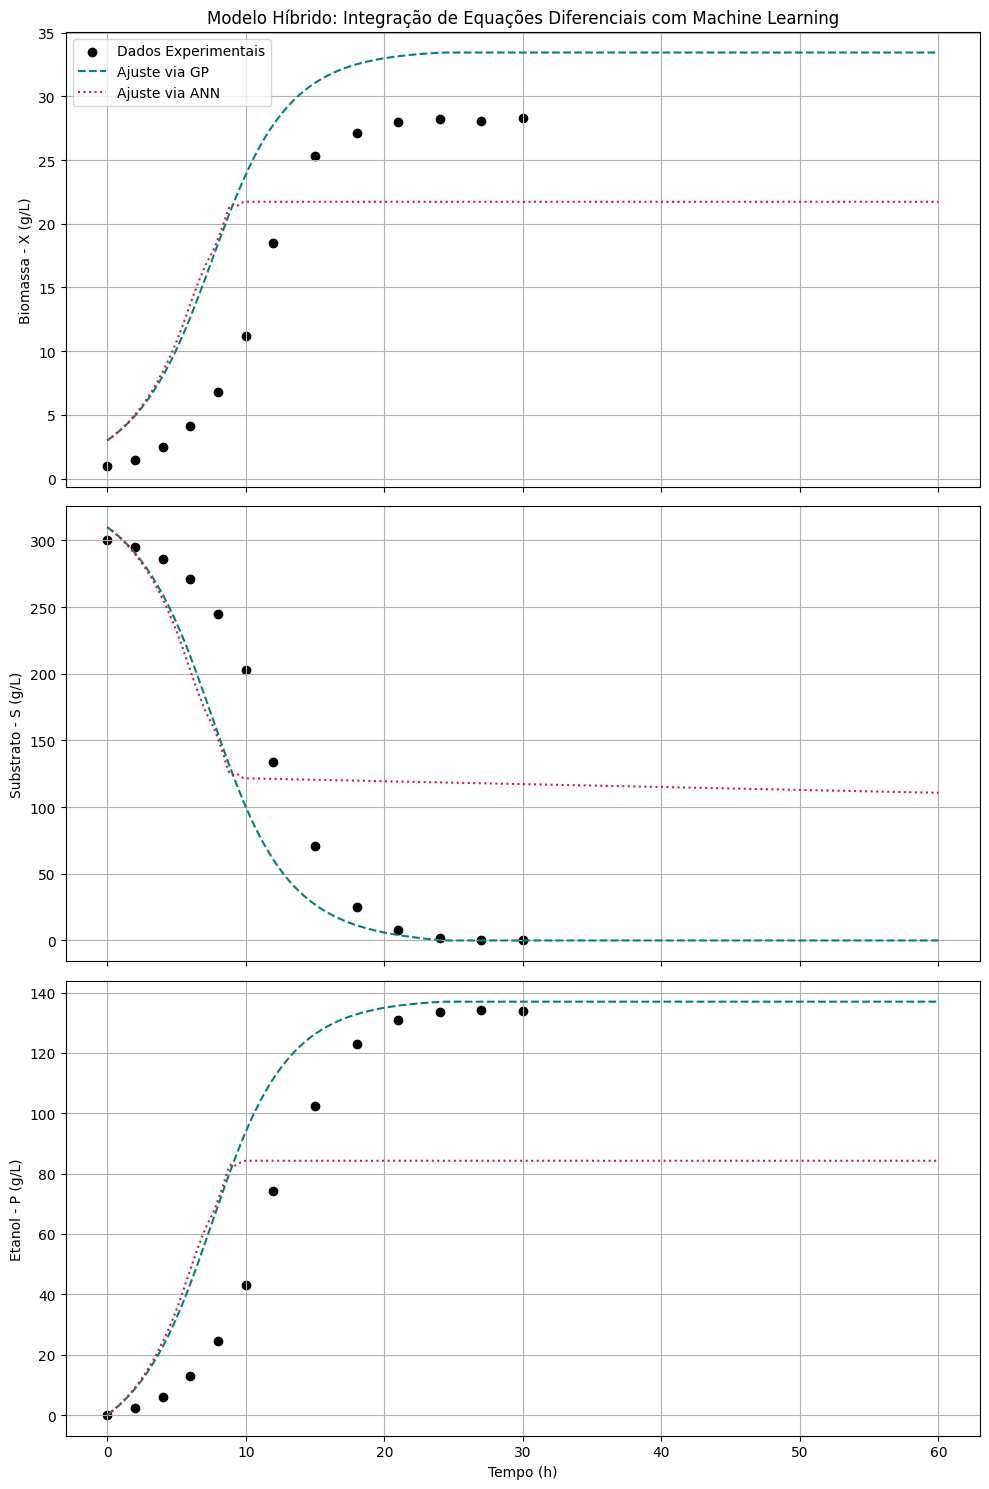

In [ ]:
# --- 6. Plotagem Comparativa Final ---

fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

# Plot dos dados experimentais (reais)
axes[0].scatter(t_data, X_data, color='black', marker='o', label='Dados Experimentais')
axes[1].scatter(t_data, S_data, color='black', marker='o')
axes[2].scatter(t_data, P_data, color='black', marker='o')

# Trajetória híbrida GP
axes[0].plot(sol_gp.t, sol_gp.y[0], label='Ajuste via GP', color='teal', linestyle='--')
axes[1].plot(sol_gp.t, sol_gp.y[1], color='teal', linestyle='--')
axes[2].plot(sol_gp.t, sol_gp.y[2], color='teal', linestyle='--')

# Trajetória híbrida ANN
axes[0].plot(sol_ann.t, sol_ann.y[0], label='Ajuste via ANN', color='crimson', linestyle=':')
axes[1].plot(sol_ann.t, sol_ann.y[1], color='crimson', linestyle=':')
axes[2].plot(sol_ann.t, sol_ann.y[2], color='crimson', linestyle=':')

axes[0].set_ylabel('Biomassa - X (g/L)')
axes[0].legend()
axes[0].grid(True)
axes[0].set_title('Modelo Híbrido: Integração de Equações Diferenciais com Machine Learning')

axes[1].set_ylabel('Substrato - S (g/L)')
axes[1].grid(True)

axes[2].set_ylabel('Etanol - P (g/L)')
axes[2].set_xlabel('Tempo (h)')
axes[2].grid(True)

plt.tight_layout()
plt.show()
